# Détection de fraude bancaire : du score au gain en euros

**Question métier :** combien de pertes une banque peut-elle éviter avec un modèle de détection, et combien d'alertes ses analystes doivent-ils traiter pour y arriver ?

Ce notebook raconte l'analyse pas à pas. Le code réutilisable est dans `src/fraud/`, les requêtes dans `sql/`.
Pré-requis : `python scripts/run_sql.py` (crée la base DuckDB) puis `python scripts/run_pipeline.py` (sensibilité, exports).

**Plan**
1. Qualité des données (SQL)
2. Où se concentrent les pertes ? (SQL)
3. Pourquoi l'accuracy ne veut rien dire ici
4. Découpage temporel et modèles
5. Choisir le seuil en euros, pas en probabilité
6. Résultats sur la période de test
7. Sensibilité au coût d'une alerte
8. Limites et suite

In [1]:
import sys
from pathlib import Path

import duckdb
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from fraud import config, costs, data, features, models

pd.set_option("display.float_format", "{:,.2f}".format)
con = duckdb.connect(str(ROOT / "data" / "fraud.duckdb"), read_only=True)

## 1. Qualité des données

Avant toute analyse : volumétrie, valeurs manquantes, doublons. La table `transactions` a été construite par `sql/00_load.sql` (doublons exacts supprimés, première occurrence conservée).

In [2]:
con.sql("""
    SELECT
        (SELECT COUNT(*) FROM transactions_raw)                       AS lignes_brutes,
        (SELECT COUNT(*) FROM transactions)                           AS lignes_nettoyees,
        (SELECT COUNT(*) FROM transactions_raw)
          - (SELECT COUNT(*) FROM transactions)                       AS doublons_supprimes,
        (SELECT SUM("Class") FROM transactions_raw)
          - (SELECT SUM("Class") FROM transactions)                   AS fraudes_en_double,
        (SELECT ROUND(100 * AVG("Class"), 3) FROM transactions)       AS taux_fraude_pct
""").df()

,lignes_brutes,lignes_nettoyees,doublons_supprimes,fraudes_en_double,taux_fraude_pct
0,284807,283726,1081,19.00,0.17


**À retenir**
- 1 081 transactions sont des doublons exacts, dont 19 fraudes. Sans ce nettoyage, une même fraude pourrait se retrouver à la fois dans l'apprentissage et dans le test : le score serait artificiellement bon.
- Aucune valeur manquante (voir `reports/sql_results/dq_overview.csv`).
- Après nettoyage : 473 fraudes sur 283 726 transactions, soit **0,167 %**. Le jeu est extrêmement déséquilibré.
- Les montants sont présentés en euros (cartes européennes, septembre 2013) ; la devise n'est pas précisée explicitement par la source.

## 2. Où se concentrent les pertes ?

Découpage des transactions en 10 tranches de montant de même effectif (`NTILE`), puis cumul des pertes (`SUM() OVER`).

In [3]:
con.sql("""
    WITH deciles AS (
        SELECT *, NTILE(10) OVER (ORDER BY "Amount", tx_id) AS decile
        FROM transactions
    )
    SELECT
        decile,
        ROUND(MIN("Amount"), 2)                                   AS montant_min,
        ROUND(MAX("Amount"), 2)                                   AS montant_max,
        SUM("Class")                                              AS nb_fraudes,
        ROUND(SUM(CASE WHEN "Class" = 1 THEN "Amount" END), 0)    AS pertes_eur,
        ROUND(100 * SUM(CASE WHEN "Class" = 1 THEN "Amount" END)
              / SUM(SUM(CASE WHEN "Class" = 1 THEN "Amount" END)) OVER (), 1) AS part_pertes_pct
    FROM deciles
    GROUP BY decile
    ORDER BY decile
""").df()

,decile,montant_min,montant_max,nb_fraudes,pertes_eur,part_pertes_pct
0,1,0.00,1.00,165.00,126.00,0.20
1,2,1.00,3.58,32.00,56.00,0.10
2,3,3.58,8.92,36.00,221.00,0.40
3,4,8.92,13.05,13.00,140.00,0.20
4,5,13.05,22.00,14.00,257.00,0.40
5,6,22.00,37.07,16.00,468.00,0.80
6,7,37.07,59.90,23.00,"1,057.00",1.80
7,8,59.90,100.00,49.00,"4,533.00",7.70
8,9,100.00,203.38,43.00,"5,850.00",10.00
9,10,203.39,"25,691.16",82.00,"45,885.00",78.30


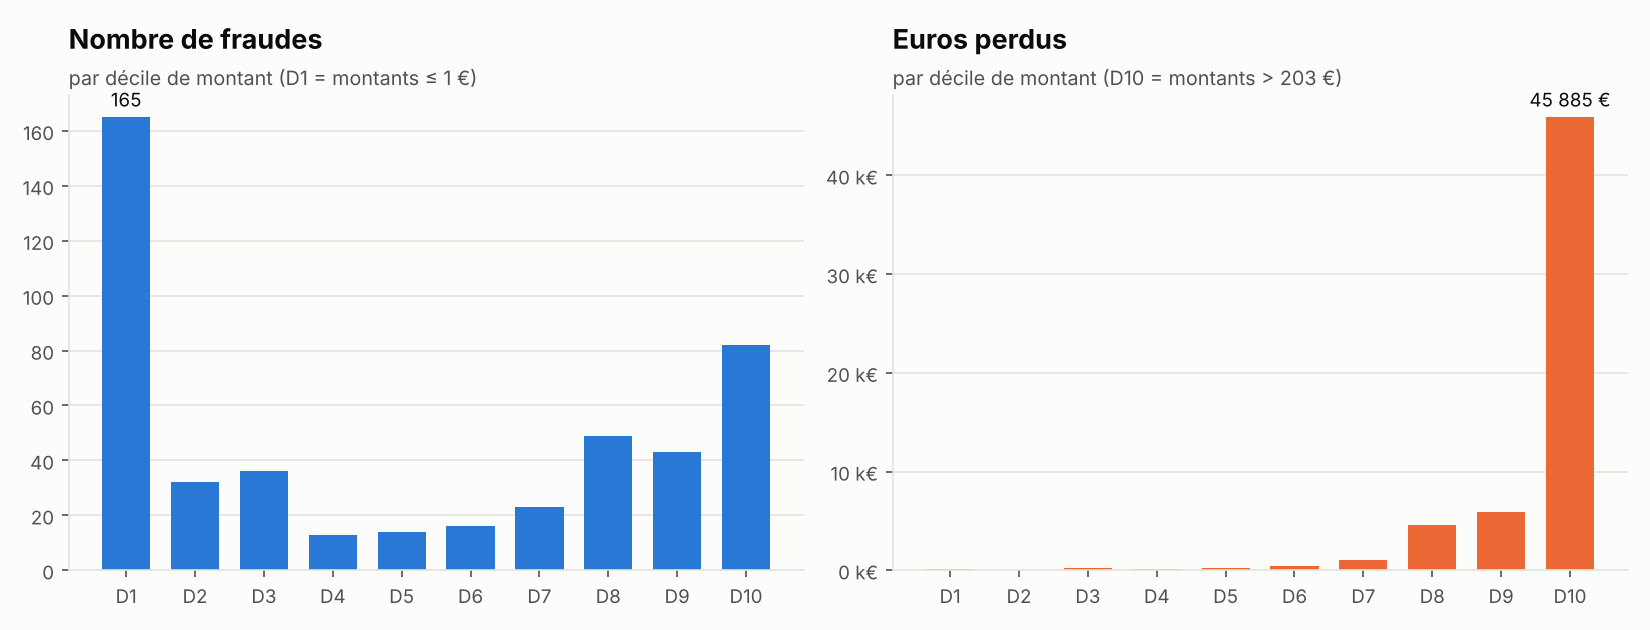

In [4]:
display(Image(filename=str(config.FIGURES_DIR / "01_fraud_by_amount_decile.png")))

**C'est l'observation clé du projet : compter les fraudes et compter les euros donnent deux images opposées.**

- 171 fraudes (36 % du total) portent sur des montants **≤ 1 €**. C'est la signature classique du *card testing* : le fraudeur vérifie qu'une carte volée fonctionne avant de s'en servir. Ces fraudes coûtent presque rien (132 € au total).
- À l'inverse, les 10 % de transactions les plus élevées (> 203 €) concentrent **78 % des pertes** (45 885 € sur 58 591 €).
- Plus globalement, 20 % des fraudes représentent 82 % des pertes (`reports/sql_results/fraud_pareto.csv`).

Conséquence : un modèle évalué au **nombre** de fraudes détectées peut être excellent sur le papier et médiocre en euros. Le projet évalue donc tout **en euros**.

## 3. Pourquoi l'accuracy ne veut rien dire ici

In [5]:
taux_fraude = con.sql('SELECT AVG("Class") FROM transactions').fetchall()[0][0]
print(f"Un 'modèle' qui ne signale JAMAIS de fraude a une accuracy de {1 - taux_fraude:.2%}")
print("... et il laisse passer 100 % des pertes.")

Un 'modèle' qui ne signale JAMAIS de fraude a une accuracy de 99.83%
... et il laisse passer 100 % des pertes.


On utilise donc :
- la **PR-AUC** (aire sous la courbe précision-rappel) pour comparer la capacité des modèles à classer les transactions, car elle se concentre sur la classe rare ;
- le **gain net en euros** pour décider, car c'est ce qui intéresse la banque.

## 4. Découpage temporel et modèles

En production, un modèle est entraîné sur le passé et utilisé sur le futur. On reproduit cette situation :

| Période | Rôle | Usage |
|---|---|---|
| 60 % les plus anciens | apprentissage | entraîner les modèles |
| 20 % suivants | validation | choisir le modèle et le seuil d'alerte |
| 20 % les plus récents | test | mesurer le résultat final, **une seule fois** |

In [6]:
con.sql("SELECT * FROM read_csv('" + str(ROOT / "reports/sql_results/split_summary.csv") + "')").df()

,split,start_hour,end_hour,n_transactions,n_fraud,fraud_rate_pct,fraud_amount_eur
0,1_train,0.00,33.40,170236,342.00,0.20,"38,632.63"
1,2_validation,33.40,40.30,56746,57.00,0.10,"12,231.09"
2,3_test,40.30,48.00,56744,74.00,0.13,"7,727.67"


Quatre approches sont comparées :

1. **Règle montant** : on contrôle les plus gros montants. C'est la référence « sans data science ».
2. **Régression logistique** : modèle linéaire simple et interprétable.
3. **LightGBM** : gradient boosting, capte les interactions non linéaires.
4. **LightGBM pondéré €** : même modèle, mais chaque fraude pèse dans l'apprentissage proportionnellement à son montant. On dit explicitement au modèle qu'une fraude à 1 000 € compte plus qu'une fraude à 1 €.

In [7]:
raw = data.load_raw()
df = data.clean(raw)
splits = data.temporal_split(df)
X = {k: features.build_features(v) for k, v in splits.items()}
y = {k: v["Class"] for k, v in splits.items()}
amt = {k: v["Amount"] for k, v in splits.items()}

fitted = models.fit_all(X["train"], y["train"], amt["train"])
scores = {name: {s: m.predict_proba(X[s])[:, 1] for s in ("valid", "test")} for name, m in fitted.items()}
print("Modèles entraînés :", list(fitted))

Modèles entraînés : ['Règle montant', 'Régression logistique', 'LightGBM', 'LightGBM pondéré €']


## 5. Choisir le seuil en euros, pas en probabilité

Un modèle donne un score de risque. Le seuil (« à partir de quel score j'envoie une alerte ? ») est une **décision métier**. Le seuil par défaut de 0,5 n'a aucune justification.

Hypothèses de coût (`src/fraud/config.py`) :
- chaque alerte coûte **5 €** (environ 5 minutes d'analyste à 60 €/h chargé) ;
- une fraude détectée évite la perte de son montant ;
- une fraude manquée coûte son montant (remboursement du client).

**Gain net = euros de fraude évités − nombre d'alertes × 5 €.** Pour chaque modèle, on teste tous les seuils possibles sur la période de validation et on garde celui qui maximise le gain net.

In [8]:
valid_curves, thresholds = {}, {}
for name in fitted:
    curve = costs.threshold_curve(y["valid"], amt["valid"], scores[name]["valid"], config.REVIEW_COST_EUR)
    valid_curves[name] = curve
    thresholds[name] = costs.best_threshold(curve)

pd.DataFrame({
    name: valid_curves[name].loc[valid_curves[name]["threshold"] == t,
                                 ["n_alerts", "n_fraud_caught", "fraud_amount_saved", "net_savings"]].iloc[0]
    for name, t in thresholds.items()
}).T.rename(columns={"n_alerts": "alertes", "n_fraud_caught": "fraudes détectées",
                     "fraud_amount_saved": "€ évités", "net_savings": "gain net (validation)"})

,alertes,fraudes détectées,€ évités,gain net (validation)
Règle montant,414.00,2.00,"3,460.87","1,390.87"
Régression logistique,42.00,38.00,"7,689.23","7,479.23"
LightGBM,52.00,43.00,"7,756.23","7,496.23"
LightGBM pondéré €,255.00,48.00,"8,964.91","7,689.91"


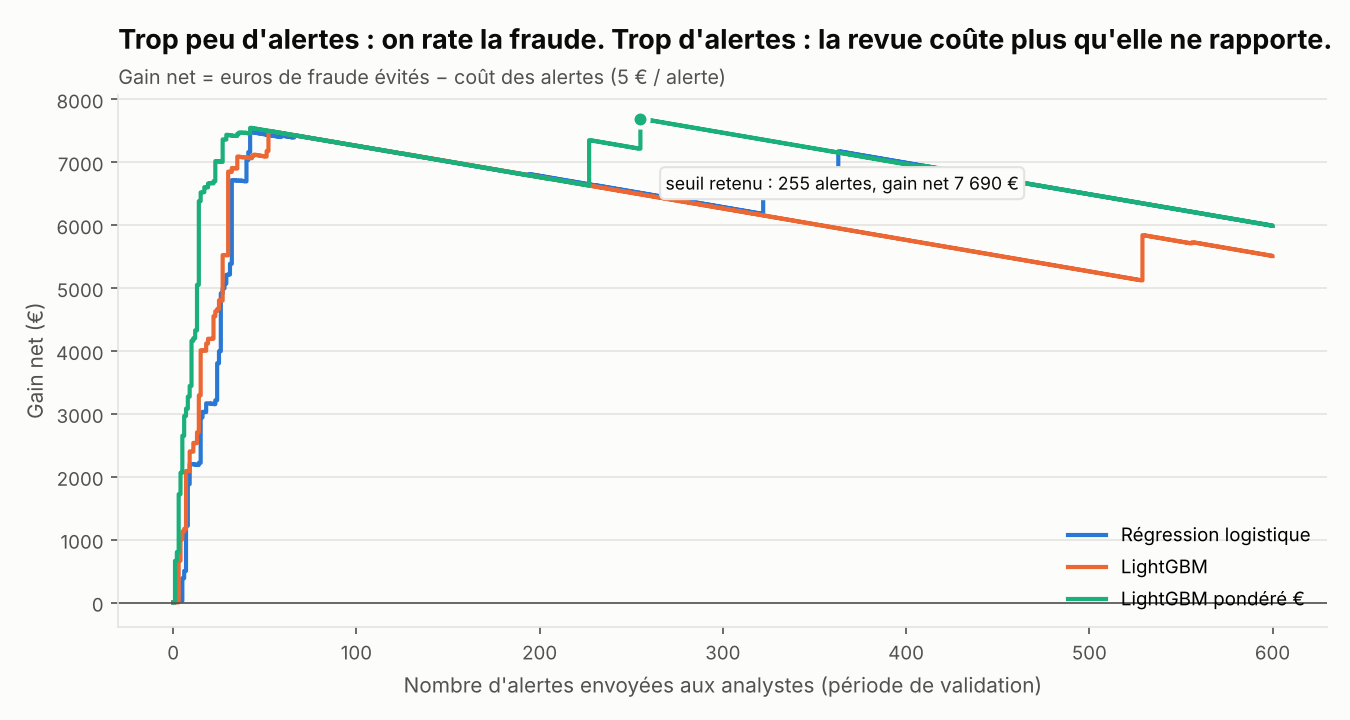

In [9]:
display(Image(filename=str(config.FIGURES_DIR / "02_net_savings_vs_alerts.png")))

La courbe monte très vite (les premières alertes sont presque toutes des fraudes coûteuses), atteint un plateau, puis redescend lentement : chaque alerte supplémentaire coûte 5 € et rapporte de moins en moins.

**Modèle retenu :** celui qui a le meilleur gain net en validation, soit **LightGBM pondéré €**. Le test n'a pas servi à ce choix.

## 6. Résultats sur la période de test (jamais vue)

Le seuil choisi en validation est appliqué tel quel. Comme le test ne contient que 74 fraudes, chaque gain est accompagné d'un **intervalle de confiance à 90 %** obtenu par bootstrap.

In [10]:
rows = []
for name in fitted:
    flagged = scores[name]["test"] >= thresholds[name]
    out = costs.business_outcome(y["test"], amt["test"], flagged, config.REVIEW_COST_EUR)
    lo, hi = costs.bootstrap_net_savings(y["test"], amt["test"], flagged, config.REVIEW_COST_EUR)
    rows.append({"approche": name, "alertes": out["n_alerts"],
                 "fraudes détectées": f"{out['n_fraud_caught']}/{out['n_fraud']}",
                 "précision": out["precision"], "€ évités": out["fraud_amount_saved"],
                 "gain net": out["net_savings"], "IC90 bas": lo, "IC90 haut": hi,
                 "pertes évitées": out["loss_reduction_pct"]})
results = pd.DataFrame(rows).set_index("approche")
results

,alertes,fraudes détectées,précision,€ évités,gain net,IC90 bas,IC90 haut,pertes évitées
approche,,,,,,,,
Règle montant,276,1/74,0.00,"1,504.93",124.93,"-1,460.00","3,119.79",0.02
Régression logistique,49,47/74,0.96,"4,657.04","4,412.04","1,579.41","7,790.17",0.57
LightGBM,62,54/74,0.87,"5,044.60","4,734.60","1,825.62","8,225.29",0.61
LightGBM pondéré €,308,63/74,0.20,"5,991.55","4,451.55","1,374.28","8,087.05",0.58


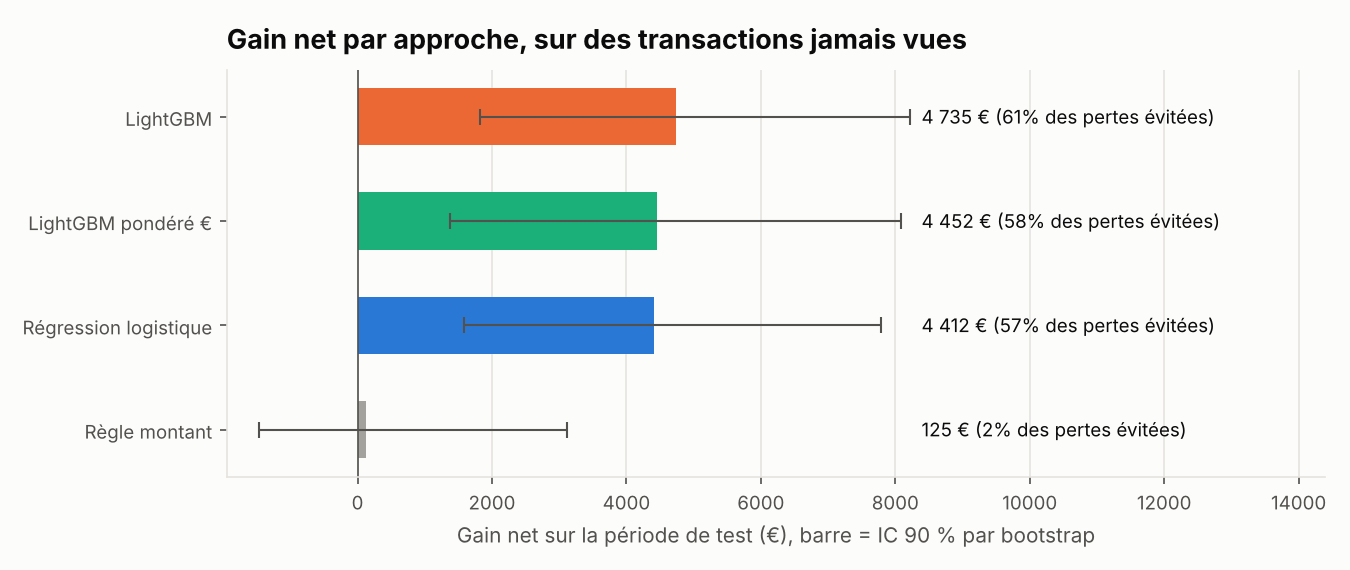

In [11]:
display(Image(filename=str(config.FIGURES_DIR / "03_model_comparison_test.png")))

**Lecture honnête des résultats**

- **La règle sur le montant ne sert à rien** (gain ≈ 0). Le montant seul ne distingue pas une fraude d'un achat légitime. Le modèle apporte donc une vraie valeur.
- **Les trois modèles évitent environ 57 à 61 % des pertes** sur une période jamais vue, soit 4 400 à 4 700 € sur 7 728 € de fraude en 7,7 heures.
- **Leurs intervalles de confiance se chevauchent largement** : avec 74 fraudes en test, on ne peut pas affirmer qu'un modèle ML bat les autres. Le modèle retenu en validation (LightGBM pondéré €) n'est d'ailleurs pas le meilleur sur le test. C'est normal, et c'est précisément pour ça qu'on ne choisit pas un modèle sur le test.
- **La vraie différence est opérationnelle.** Pour un gain comparable, LightGBM pondéré € génère environ 40 alertes par heure (précision de 20 %), alors que LightGBM simple en génère 8 par heure (précision de 87 %). Si l'équipe de revue est limitée, LightGBM simple est le bon choix.

## 7. Sensibilité au coût d'une alerte

Le coût de 5 € est une hypothèse. Que se passe-t-il s'il est plus faible (confirmation automatique par SMS) ou plus élevé (appel client, blocage de carte) ? Pour chaque coût, le seuil est ré-optimisé sur la validation, puis appliqué au test. Calcul dans `scripts/run_pipeline.py`.

In [12]:
sens = pd.read_csv(config.REPORTS_DIR / "sensitivity.csv")
sens.pivot(index="review_cost", columns="model", values="net_savings").round(0)

model,LightGBM,LightGBM pondéré €,Régression logistique
review_cost,,,
1.00,"4,581.00","4,894.00","5,005.00"
2.00,"4,921.00","5,376.00","4,650.00"
5.00,"4,735.00","4,452.00","4,412.00"
10.00,"4,425.00","4,506.00","4,167.00"
20.00,"3,805.00","4,120.00","3,677.00"


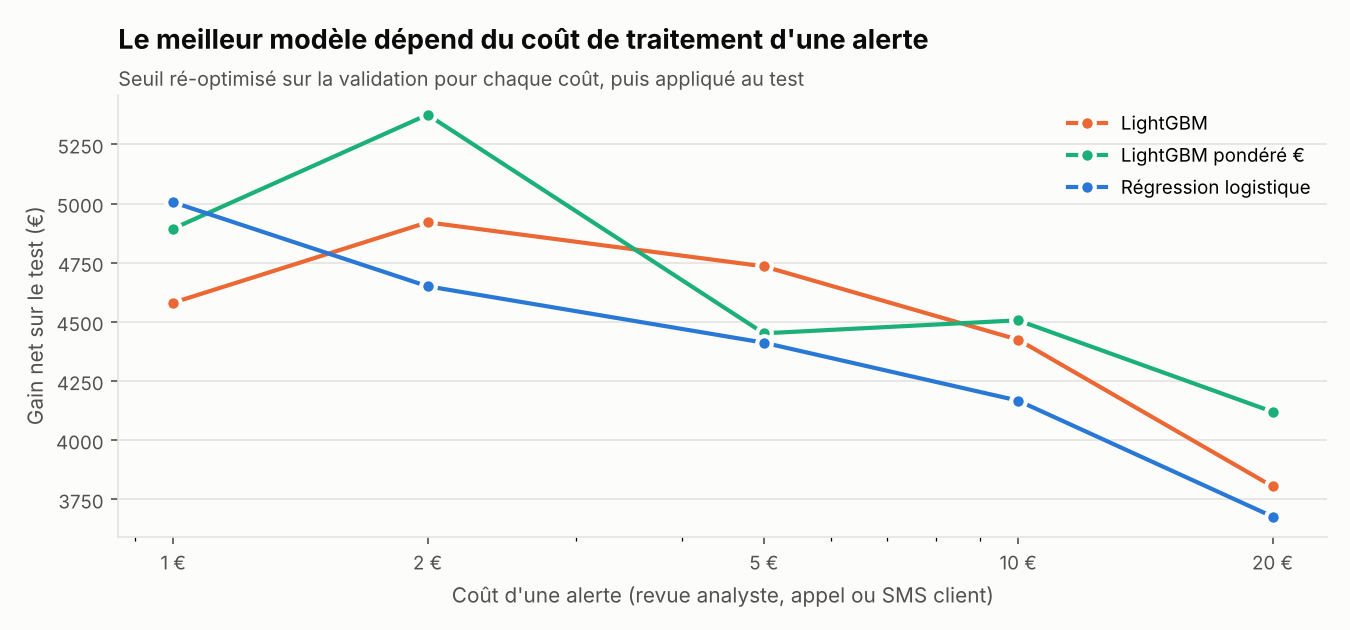

In [13]:
display(Image(filename=str(config.FIGURES_DIR / "04_sensitivity_review_cost.png")))

- Plus une alerte coûte cher, plus le seuil monte et moins on alerte : le gain net baisse, mais reste élevé (environ 3 700 à 4 100 € à 20 € l'alerte).
- La version pondérée en euros arrive en tête dans 3 scénarios sur 5, avec des écarts faibles au regard de l'incertitude.
- **Recommandation :** le paramètre qui pèse le plus sur la décision n'est pas le choix de l'algorithme, c'est le **coût réel d'une alerte et la capacité de l'équipe**. C'est le premier chiffre à obtenir auprès du métier.

## 8. Limites et suite

**Limites**
- Seulement 2 jours de données (2013) : impossible de mesurer la dérive dans le temps ou la saisonnalité.
- Les variables V1 à V28 sont anonymisées par ACP. On sait quelles variables comptent (V14, V10, V17, voir `reports/figures/05_feature_importance.png`), mais pas ce qu'elles représentent. Impossible donc d'expliquer une alerte à un analyste.
- Le coût d'une alerte est une hypothèse, et le coût de la gêne client (carte bloquée à tort) n'est pas modélisé.
- 74 fraudes en test : les résultats donnent un ordre de grandeur, pas une certitude.

**Suite logique en entreprise**
- Mesurer le coût réel d'une alerte et la capacité de l'équipe, puis ajouter une contrainte de capacité (nombre maximal d'alertes par heure).
- Suivre en production le taux d'alerte, la précision et les euros évités dans un dashboard (voir `powerbi/`).
- Ré-entraîner régulièrement et surveiller la dérive des scores.